In [344]:
import numpy as np
from scipy.fft import fft
from scipy.signal import welch, periodogram

In [345]:
#####################
# 1TE651 Signal Processing 
# Assignment: Active Noise Cancellation with LMS 
# This script is used to cancel noise from a noisy music signal using the normalized LMS algorithm. See the assingment description for more details.
##################
# STODO indicates the parts of the code that the students need to complete.
##################
#  NOTE: We implemented two options for loading/recording of audio files. One uses the soundfile library, while the other uses the torchaudio library. You can choose the desired option by setting the audio_library variable to 'lib_sd' or 'lib_torch'. There is no difference in the output between the two options. We have provided the code for both options to ensure that the code runs on different platforms. (Soundfile seems to have problems on some macos machines.)
###################


import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sc
audio_library = 'lib_sd'  # 'lib_sd' or 'lib_torch'
if audio_library == 'lib_sd':
    import soundfile as sf
elif audio_library == 'lib_torch':
    import torchaudio
    import torch


# Choose noise scenario, possible values: 1,2,3,4 
mynoiseScenario=2

# Create file path assuming DATASETA is a subfolder of your current  directory
noisefile = f'./DATASETA/N{mynoiseScenario}.wav' 
signalfile = f'./DATASETA/vocalN{mynoiseScenario}.wav'

# Read noise recording
# w: sampled noise, Fs: sampling rate (same both w and xw),
if audio_library == 'lib_sd':
   w, Fs = sf.read(noisefile)    
elif audio_library == 'lib_torch':
  wt, Fs =torchaudio.load(noisefile)
  w=wt.detach().numpy()
# w=w.reshape(-1, 1)

# Read signal (music+noise) recording
# xw: sampled music+noise
if audio_library == 'lib_sd':
   xw, _ = sf.read(signalfile)    
elif audio_library == 'lib_torch':
  xwt, _ = torchaudio.load(signalfile) 
  xw=xwt.detach().numpy()
# xw=xw.reshape(-1, 1)

In [ ]:
sample_length = len(xw)
ds = 10/sample_length
beta = 1/2
epsilon = 0.005
p = 200
h = np.zeros((sample_length, p))
w_n = 0
recx = np.zeros(sample_length)

for i in range(p, sample_length):
  i_p = i-p+1
  w_f = np.flip(w[i_p:i+1])
  w_n = h[i-1, :].T@w_f
  e = xw[i] - w_n
  recx[i] = e
  h[i, :] = h[i-1, :] + beta * (w_f/(np.linalg.norm(w[i_p:i+1])**2 + epsilon))*e
recx=recx.reshape(-1, 1)

In [ ]:
# recx=recx*1337
recfile = f'recvocalN{mynoiseScenario}.wav'
if audio_library == 'lib_sd':
   sf.write(recfile,recx,Fs)
elif audio_library == 'lib_torch':
  recxt=torch.from_numpy(recx)
  recxtt=torch.reshape(recxt, (1,-1))
  torchaudio.save(recfile, recxtt, Fs)

#### Plottar

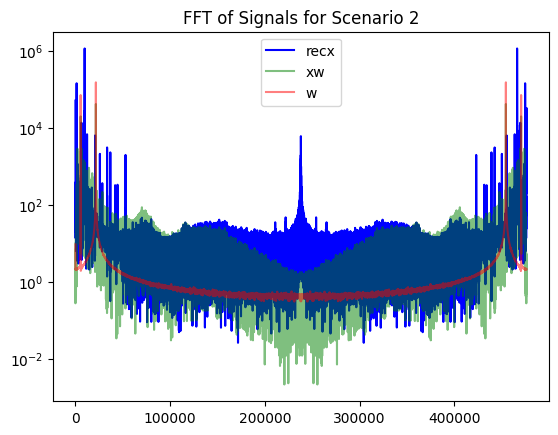

In [ ]:
plt.title(f'FFT of Signals for Scenario {mynoiseScenario}')
plt.semilogy(np.abs(fft(recx, axis=0)) , color = 'blue', label = 'recx')
plt.semilogy(np.abs(fft(xw, axis=0)), color = 'green', label = 'xw', alpha=0.5)
plt.semilogy(np.abs(fft(w, axis=0)), color = 'red', label = 'w', alpha=0.5)
plt.legend()
plt.show()

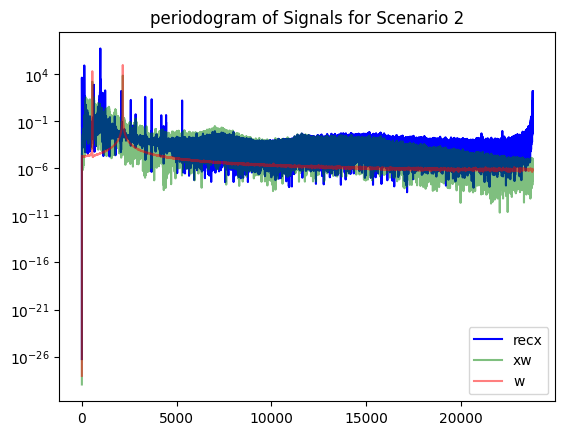

In [ ]:
plt.title(f'periodogram of Signals for Scenario {mynoiseScenario}')
plt.semilogy(periodogram(recx, axis=0, fs=1/ds)[0], periodogram(recx, axis=0)[1] , color = 'blue', label = 'recx')
plt.semilogy(periodogram(xw, fs=1/ds)[0], periodogram(xw)[1], color = 'green', label = 'xw', alpha=0.5)
plt.semilogy(periodogram(w, fs=1/ds)[0], periodogram(w)[1], color = 'red', label = 'w', alpha=0.5)
plt.legend()
plt.show()

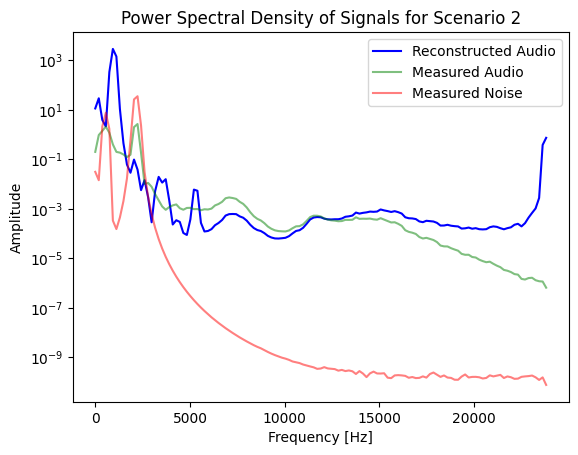

In [ ]:
plt.title(f'Power Spectral Density of Signals for Scenario {mynoiseScenario}')
plt.semilogy(welch(recx, axis=0, fs=1/ds)[0], welch(recx, axis=0)[1].flatten(), color = 'blue', label = 'Reconstructed Audio')
plt.semilogy(welch(xw, fs=1/ds)[0], welch(xw)[1], color = 'green', label = 'Measured Audio', alpha=0.5)
plt.semilogy(welch(w, fs=1/ds)[0], welch(w)[1], color = 'red', label = 'Measured Noise', alpha=0.5)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Amplitude')
plt.legend()
plt.savefig(f"welch_{p}_{beta}_{epsilon}_{mynoiseScenario}.pdf")
plt.show()

#### Första version

Helt galen men funkar ganska bra också blir lite burkigt dock

In [ ]:
# sample_length = len(xw)
# beta = 1
# epsilon = 0.005
# p = 50
# h = np.zeros(p)
# w_n = 0
# mu = 0
# recx = np.zeros(sample_length)

# for i in range(sample_length):
#   i_p = max(0, i-p+1)
#   w_n = h[0: min(p, i+1)].T@np.flip(w[i_p:i+1])
#   e = xw[i] - w_n
#   recx[i] = e
#   h[0:min(p, i+1)] = h[0:min(p, i+1)] + beta * (np.flip(w[i_p:i+1])/(np.linalg.norm(w[i_p:i+1])**2 + epsilon))*e
